# Pre define

In [1]:

from pathlib import Path
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle, FancyArrowPatch
from matplotlib.transforms import Bbox
from IPython.display import display

BASE = Path("/data/hulei/OmicOS")
OUT = BASE / "OmicOS_5"
FIG = OUT / "figures"
PANEL = FIG 
TAB = OUT / "outputs" / "tables"
ART = OUT / "outputs" / "artifacts"
REP = OUT / "outputs" / "report"
LOG = OUT / "outputs" / "logs"
for d in [FIG, PANEL, TAB, ART, REP, LOG]:
    d.mkdir(parents=True, exist_ok=True)

P1 = BASE / "OmicOS_1" / "outputs"
P2 = BASE / "OmicOS_2" / "outputs"
P3 = BASE / "OmicOS_3" / "outputs"
WSI = BASE / "Data" / "Visium_HD_Human_Lung_Cancer_Fixed_Frozen_tissue_image.btf"

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans", "Liberation Sans"],
    "font.size": 18,
    "axes.titlesize": 18,
    "axes.labelsize": 18,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.fontsize": 18,
    "axes.linewidth": 0.7,
    "axes.titlepad": 3.0,
    "lines.linewidth": 1.2,
    "patch.linewidth": 0.7,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

DOMAIN_COLORS = [
    "#1f77b4", "#ffbf00", "#2ca02c", "#d62728", "#9467bd", "#17becf",
    "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#003f5c", "#ffa600",
    "#4daf4a", "#984ea3", "#f781bf", "#a65628", "#999999", "#66c2a5",
]
SEMANTIC_COLORS = {
    "tumor_epithelium": "#1f77b4",
    "fibrotic_stroma": "#ffbf00",
    "immune_inflammation": "#2ca02c",
    "blood_vessel": "#17becf",
    "alveolar_airspace": "#9467bd",
    "necrosis_detritus": "#d62728",
    "bronchial_structure": "#8c564b",
}
MARKER_GROUPS = [
    "epithelial_tumor", "stromal_ecm", "immune", "vascular",
    "proliferation", "hypoxia_stress",
]
MARKER_COLORS = {
    "epithelial_tumor": "#1f77b4",
    "stromal_ecm": "#ffbf00",
    "immune": "#2ca02c",
    "vascular": "#17becf",
    "proliferation": "#9467bd",
    "hypoxia_stress": "#d62728",
}


def read_csv(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)
    return pd.read_csv(path)


def read_json(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)
    with path.open() as fh:
        return json.load(fh)


def natural_key(value):
    text = str(value)
    try:
        return (0, float(text.replace("um", "")))
    except ValueError:
        return (1, text)


def panel_label(ax, label):
    label = str(label).lower()
    ax._panel_label = label
    ax.text(-0.065, 1.03, label, transform=ax.transAxes, fontsize=18, fontweight="bold", va="bottom", ha="left")


def clean_axis(ax):
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_facecolor("white")


def row_zscore(frame):
    arr = frame.to_numpy(dtype=float)
    mu = np.nanmean(arr, axis=1, keepdims=True)
    sd = np.nanstd(arr, axis=1, keepdims=True)
    sd[sd == 0] = 1
    return pd.DataFrame((arr - mu) / sd, index=frame.index, columns=frame.columns)


def heatmap(ax, frame, title, cmap="viridis", vmin=None, vmax=None, annotate=False, fmt=".2f"):
    im = ax.imshow(frame.to_numpy(dtype=float), aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_xticks(range(frame.shape[1]))
    ax.set_xticklabels([str(c) for c in frame.columns], rotation=45, ha="right")
    ax.set_yticks(range(frame.shape[0]))
    ax.set_yticklabels([str(i) for i in frame.index])
    if annotate and frame.shape[0] * frame.shape[1] <= 90:
        for i in range(frame.shape[0]):
            for j in range(frame.shape[1]):
                val = frame.iloc[i, j]
                if np.isfinite(val):
                    ax.text(j, i, format(val, fmt), ha="center", va="center", fontsize=7.2)
    return im


def add_colorbar(fig, im, ax, label=None):
    cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.012)
    cb.ax._skip_panel = True
    cb.ax.tick_params(labelsize=7.6, length=2.0, pad=1.5)
    if label:
        cb.set_label(label)
    return cb


def _safe_name(text):
    safe = "".join(ch.lower() if ch.isalnum() else "_" for ch in str(text)).strip("_")
    while "__" in safe:
        safe = safe.replace("__", "_")
    return safe[:46] or "panel"


def save_axes_panels(fig, stem):
    panel_dir = PANEL / stem
    panel_dir.mkdir(parents=True, exist_ok=True)
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    saved = []
    for idx, ax in enumerate(fig.axes, start=1):
        if getattr(ax, "_skip_panel", False):
            continue
        if not ax.get_visible():
            continue
        bbox = ax.get_tightbbox(renderer).transformed(fig.dpi_scale_trans.inverted()).expanded(1.04, 1.08)
        label = getattr(ax, "_panel_label", None)
        title = ax.get_title() or f"axis_{idx:02d}"
        name = f"{label}_" if label else f"panel_{idx:02d}_"
        out = panel_dir / f"{name}{_safe_name(title)}.png"
        fig.savefig(out, bbox_inches=bbox, pad_inches=0.015)
        saved.append(str(out))
    with (panel_dir / "panel_manifest.json").open("w") as fh:
        json.dump({"figure": stem, "panels": saved}, fh, indent=2)
    return saved


def save_and_display(fig, stem):
    png = FIG / f"{stem}.png"
    pdf = FIG / f"{stem}.pdf"
    save_axes_panels(fig, stem)
    fig.savefig(png, bbox_inches="tight", pad_inches=0.025)
    fig.savefig(pdf, bbox_inches="tight", pad_inches=0.025)
    display(fig)
    plt.close(fig)
    print(f"saved: {png}")
    print(f"saved: {pdf}")


def categorical_spatial(ax, df, column, title, x="center_x", y="center_y", size=2.0, palette=None, legend=True):
    vals = df[column].astype(str)
    cats = sorted(vals.dropna().unique(), key=natural_key)
    if palette is None:
        color_map = {cat: DOMAIN_COLORS[i % len(DOMAIN_COLORS)] for i, cat in enumerate(cats)}
    else:
        color_map = {cat: palette.get(cat, "#999999") for cat in cats}
    ax.scatter(df[x], df[y], c=vals.map(color_map).fillna("#cccccc"), s=size, linewidths=0, rasterized=True)
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.set_title(title)
    clean_axis(ax)
    if legend and len(cats) <= 12:
        handles = [Line2D([0], [0], marker="o", color="none", markerfacecolor=color_map[c], markersize=4, label=c) for c in cats]
        ax.legend(handles=handles, loc="lower right", frameon=False, ncol=2, handletextpad=0.2, columnspacing=0.5)


def categorical_umap(ax, df, column, title):
    vals = df[column].astype(str)
    cats = sorted(vals.dropna().unique(), key=natural_key)
    color_map = {cat: DOMAIN_COLORS[i % len(DOMAIN_COLORS)] for i, cat in enumerate(cats)}
    ax.scatter(df["umap1"], df["umap2"], c=vals.map(color_map), s=2.0, linewidths=0, rasterized=True)
    ax.set_title(title)
    ax.set_xlabel("UMAP1")
    ax.set_ylabel("UMAP2")


def continuous_spatial(ax, df, column, title, cmap="viridis", size=1.5):
    vals = df[column].astype(float)
    q1, q2 = vals.quantile([0.02, 0.98]).tolist()
    im = ax.scatter(df["center_x"], df["center_y"], c=vals, s=size, linewidths=0, cmap=cmap, vmin=q1, vmax=q2, rasterized=True)
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.set_title(title)
    clean_axis(ax)
    return im


def semantic_frequency():
    plip = read_csv(P2 / "tables" / "plip_zero_shot_tile_semantics_omicos2.csv")
    omiclip = read_csv(P3 / "tables" / "omiclip_loki_zero_shot_tiles_omicos3.csv")
    conch = read_csv(P3 / "tables" / "conch_zero_shot_tiles_omicos3.csv")
    frames = {
        "PLIP": plip["plip_semantic_label"],
        "OmiCLIP-Loki": omiclip["omiclip_loki_semantic_label"],
        "CONCH": conch["conch_semantic_label"],
    }
    out = pd.DataFrame({name: labels.value_counts(normalize=True) for name, labels in frames.items()}).T.fillna(0.0)
    out = out.reindex(columns=sorted(out.columns), fill_value=0.0)
    out.to_csv(TAB / "semantic_label_frequency_omicos5.csv")
    return out


def btf_page_info():
    import tifffile
    with tifffile.TiffFile(str(WSI)) as tf:
        page = tf.pages[0]
        return {
            "width": int(page.imagewidth),
            "height": int(page.imagelength),
            "tilewidth": int(page.tilewidth),
            "tilelength": int(page.tilelength),
        }


def build_btf_thumbnail(stride=32):
    import tifffile
    cache = ART / f"he_btf_thumbnail_stride{stride}_omicos5.npy"
    if cache.exists():
        return np.load(cache)
    with tifffile.TiffFile(str(WSI)) as tf, WSI.open("rb") as fh:
        page = tf.pages[0]
        tw, th = page.tilewidth, page.tilelength
        nx = math.ceil(page.imagewidth / tw)
        ny = math.ceil(page.imagelength / th)
        sy = math.ceil(th / stride)
        sx = math.ceil(tw / stride)
        thumb = np.zeros((ny * sy, nx * sx, 3), dtype=np.uint8)
        for idx, (off, bc) in enumerate(zip(page.dataoffsets, page.databytecounts)):
            fh.seek(off)
            tile = np.frombuffer(fh.read(bc), dtype=np.uint8).reshape(th, tw, 3)
            y = idx // nx
            x = idx % nx
            mini = tile[::stride, ::stride, :]
            thumb[y * sy:y * sy + mini.shape[0], x * sx:x * sx + mini.shape[1], :] = mini
    np.save(cache, thumb)
    return thumb


def crop_btf_region(cx, cy, size=384):
    import tifffile
    with tifffile.TiffFile(str(WSI)) as tf, WSI.open("rb") as fh:
        page = tf.pages[0]
        tw, th = page.tilewidth, page.tilelength
        w, h = page.imagewidth, page.imagelength
        nx = math.ceil(w / tw)
        x0 = max(0, int(round(cx - size / 2)))
        y0 = max(0, int(round(cy - size / 2)))
        x1 = min(w, x0 + size)
        y1 = min(h, y0 + size)
        out = np.ones((y1 - y0, x1 - x0, 3), dtype=np.uint8) * 255
        for ty in range(y0 // th, (y1 - 1) // th + 1):
            for tx in range(x0 // tw, (x1 - 1) // tw + 1):
                idx = ty * nx + tx
                fh.seek(page.dataoffsets[idx])
                tile = np.frombuffer(fh.read(page.databytecounts[idx]), dtype=np.uint8).reshape(th, tw, 3)
                sx0 = max(x0, tx * tw)
                sy0 = max(y0, ty * th)
                sx1 = min(x1, (tx + 1) * tw)
                sy1 = min(y1, (ty + 1) * th)
                out[sy0 - y0:sy1 - y0, sx0 - x0:sx1 - x0] = tile[sy0 - ty * th:sy1 - ty * th, sx0 - tx * tw:sx1 - tx * tw]
    return out


def draw_he_footprint(ax, tiles):
    info = btf_page_info()
    thumb = build_btf_thumbnail(stride=32)
    ax.imshow(thumb, extent=(0, info["width"], info["height"], 0))
    sample = tiles.iloc[::20]
    ax.scatter(sample["center_x"], sample["center_y"], s=1.0, c="#00a6d6", alpha=0.35, linewidths=0, rasterized=True)
    x0, x1 = tiles["center_x"].min(), tiles["center_x"].max()
    y0, y1 = tiles["center_y"].min(), tiles["center_y"].max()
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="#000000", linewidth=1.2))
    ax.set_title("H&E overview with tile footprint",fontsize=18)
    clean_axis(ax)


def representative_tile_rows(df, n=6):
    domains = df["smoothed_domain"].value_counts().head(n).index.tolist()
    rows = []
    for domain in domains:
        sub = df[df["smoothed_domain"].eq(domain)].copy()
        if "domain_distance" in sub.columns:
            row = sub.sort_values("domain_distance").iloc[0]
        else:
            row = sub.iloc[len(sub) // 2]
        rows.append(row)
    return pd.DataFrame(rows)


def draw_representative_tiles(fig, subspec, df):
    rows = representative_tile_rows(df, n=6)
    rows.to_csv(TAB / "representative_tile_sources_omicos5.csv", index=False)
    gs = subspec.subgridspec(2, 3, wspace=0.035, hspace=0.10)
    axes = []
    for i, (_, row) in enumerate(rows.iterrows()):
        ax = fig.add_subplot(gs[i // 3, i % 3])
        crop = crop_btf_region(row["center_x"], row["center_y"], size=384)
        ax.imshow(crop)
        ax.set_title(f"D{row['smoothed_domain']} | {row['marker_proxy_group']}", fontsize=8.3)
        clean_axis(ax)
        axes.append(ax)
    panel_label(axes[0], "E")
    return axes


def pairwise_concordance(df, cols):
    try:
        from sklearn.metrics import adjusted_rand_score
    except Exception as exc:
        raise RuntimeError("sklearn is required for pairwise concordance") from exc
    mat = pd.DataFrame(index=cols, columns=cols, dtype=float)
    for a in cols:
        for b in cols:
            mat.loc[a, b] = adjusted_rand_score(df[a].astype(str), df[b].astype(str))
    return mat


In [2]:

def finish_notebook_panel(fig, notebook, label, title):
    out_dir = PANEL / notebook
    out_dir.mkdir(parents=True, exist_ok=True)
    out = out_dir / f"{str(label).lower()}_{_safe_name(title)}.pdf"
    fig.savefig(out, bbox_inches="tight", pad_inches=0.025)
    display(fig)
    plt.close(fig)
    print(f"saved panel: {out}")


In [3]:
import omicverse as ov
import scanpy as sc
import matplotlib.pyplot as plt
ov.plot_set(font_path='Arial')
sc.settings.set_figure_params(dpi=300, vector_friendly=True)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/scanpy/_utils/__init__.py:33: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/scanpy/__init__.py:24: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/scanpy/readwrite.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):


/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (7.1.0)/charset_normalizer (3.4.3) doesn't match a supported version!
  warnings.warn(


/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/anndata/__init__.py:70: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  return module_get_attr_redirect(attr_name, deprecated_mapping=_DEPRECATED)


🔬 Starting plot initialization...
Using already downloaded Arial font from: /tmp/omicverse_arial.ttf


Registered as: Arial
🧬 Detecting GPU devices…
✅ NVIDIA CUDA GPUs detected: 8
    • [CUDA 0] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 1] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 2] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 3] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 4] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 5] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 6] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 7] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                           

# Figure B

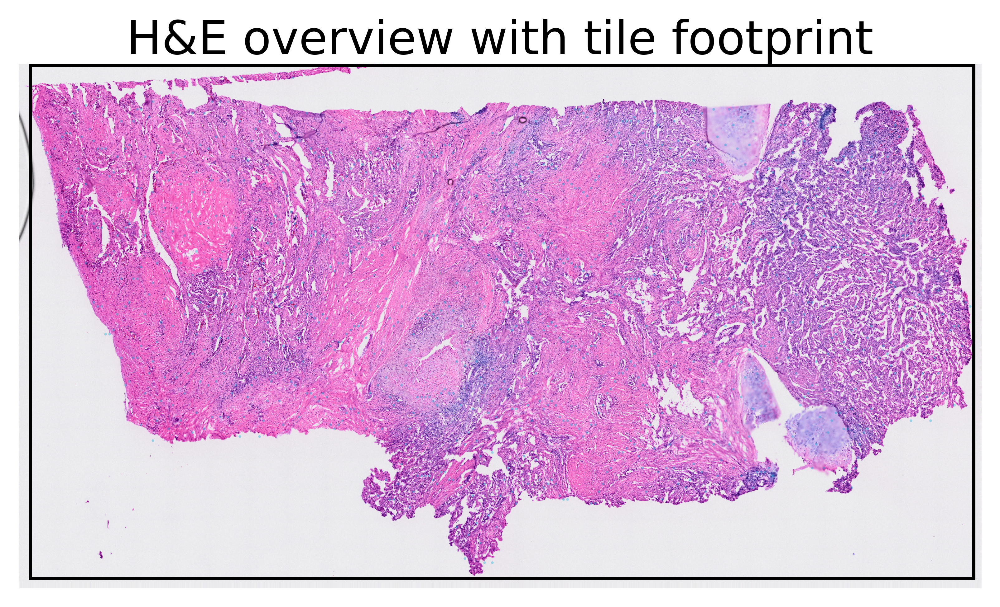

saved panel: /data/hulei/OmicOS/OmicOS_5/figures/main_figure/b_he_footprint.pdf


In [4]:
g32 = read_csv(P3 / "tables" / "gigapath_domains_32um_omicos3.csv")
fig, ax = plt.subplots(figsize=(6.6, 5.5))
#panel_label(ax, "b")
draw_he_footprint(ax, g32)
finish_notebook_panel(fig, "main_figure", "b", "he_footprint")

# Figure C

In [5]:
def categorical_spatial(
    ax,
    df,
    column,
    title,
    x="center_x",
    y="center_y",
    size=4,
    palette=None,
    legend=True,
    draw_border=True,
    border_pad_frac=0.006,
    legend_reserved_frac=0.28,
):
    vals = df[column].astype(str)
    cats = sorted(vals.dropna().unique(), key=natural_key)

    if palette is None:
        color_map = {
            cat: DOMAIN_COLORS[i % len(DOMAIN_COLORS)]
            for i, cat in enumerate(cats)
        }
    else:
        color_map = {
            cat: palette.get(cat, "#999999")
            for cat in cats
        }

    # 数据范围
    x0, x1 = df[x].min(), df[x].max()
    y0, y1 = df[y].min(), df[y].max()

    dx = x1 - x0
    dy = y1 - y0

    pad_x = dx * border_pad_frac
    pad_y = dy * border_pad_frac

    # 右侧给 legend 预留空白区域
    legend_space = dx * legend_reserved_frac if legend and len(cats) <= 12 else 0

    # 画空间点
    ax.scatter(
        df[x],
        df[y],
        c=vals.map(color_map).fillna("#cccccc"),
        s=size,
        linewidths=0,
        rasterized=True,
    )

    # 和 b 图类似的 tissue footprint 边框
    if draw_border:
        ax.add_patch(
            Rectangle(
                (x0, y0),
                dx,
                dy,
                fill=False,
                edgecolor="#000000",
                linewidth=1.2,
                zorder=10,
                clip_on=False,
            )
        )

    # 固定坐标范围
    # 右侧额外扩展 legend_space，让 legend 有地方放
    ax.set_xlim(x0 - pad_x, x1 + pad_x + legend_space)
    ax.set_ylim(y1 + pad_y, y0 - pad_y)

    ax.set_aspect("equal", adjustable="box")
    ax.set_title(title,fontsize=18)

    clean_axis(ax)

    # legend 放在 axes 内部的右侧空白区域，而不是放到图外
    if legend and len(cats) <= 12:
        handles = [
            Line2D(
                [0],
                [0],
                marker="o",
                color="none",
                markerfacecolor=color_map[c],
                markersize=15,
                label='D'+str(c),
            )
            for c in cats
        ]

        ax.legend(
            handles=handles,
            loc="center left",
            bbox_to_anchor=(0.79, 0.50),
            bbox_transform=ax.transAxes,
            frameon=False,
            ncol=12,
            handletextpad=0.25,
            columnspacing=0.65,
            borderaxespad=0.0,
            fontsize=18
        )

In [6]:
DOMAIN_COLOR_MAP_12 = {
    "0": "#8D1E54",
    "1": "#D1669D",
    "2": "#D9A3C2",
    "3": "#E37874",
    "4": "#215677",
    "5": "#2B90C7",
    "6": "#F0EDEF",
    "7": "#30824F",
    "8": "#7AB35E",
    "9": "#5A4B92",
    "10": "#E7EAC2",
    "11": "#F1B622", 
}

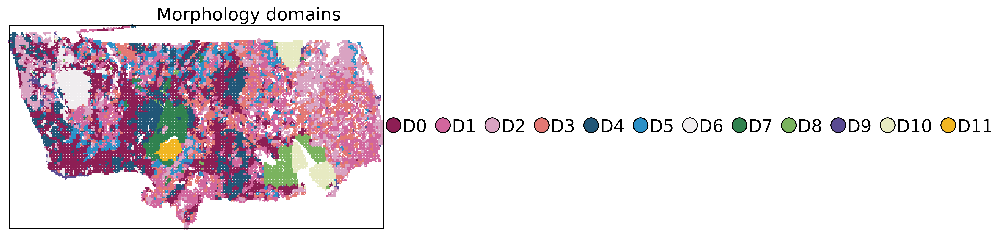

saved panel: /data/hulei/OmicOS/OmicOS_5/figures/main_figure/c_gigapath_domains.pdf


In [7]:
g32 = read_csv(P3 / "tables" / "gigapath_domains_32um_omicos3.csv")

fig, ax = plt.subplots(figsize=(8.8, 6.6))
# panel_label(ax, "c")

categorical_spatial(
    ax,
    g32,
    "smoothed_domain",
    "Morphology domains",
    palette=DOMAIN_COLOR_MAP_12,
)

finish_notebook_panel(
    fig,
    "main_figure",
    "c",
    "gigapath_domains"
)

# Figure D

In [8]:
def categorical_umap(
    ax,
    df,
    column,
    title,
    x="umap1",
    y="umap2",
    size=2.0,
    alpha=0.65,
    palette=None,
    legend=True,
    fontsize=18,
    legend_reserved_frac=0.32,
    arrow_origin=(0.08, 0.10),
    arrow_len=0.16,
):
    vals = df[column].astype(str)
    cats = sorted(vals.dropna().unique(), key=natural_key)

    if palette is None:
        color_map = {
            cat: DOMAIN_COLORS[i % len(DOMAIN_COLORS)]
            for i, cat in enumerate(cats)
        }
    else:
        color_map = {
            cat: palette.get(cat, "#999999")
            for cat in cats
        }

    # -----------------------------
    # 1. UMAP 散点图
    # -----------------------------
    ax.scatter(
        df[x],
        df[y],
        c=vals.map(color_map).fillna("#cccccc"),
        s=size,
        alpha=alpha,
        linewidths=0,
        rasterized=True,
    )

    # -----------------------------
    # 2. 固定 UMAP 数据范围，并给右侧 legend 留白
    # -----------------------------
    x0, x1 = df[x].min(), df[x].max()
    y0, y1 = df[y].min(), df[y].max()

    dx = x1 - x0
    dy = y1 - y0

    pad_x = dx * 0.04
    pad_y = dy * 0.04

    legend_space = dx * legend_reserved_frac if legend and len(cats) <= 12 else 0

    ax.set_xlim(x0 - pad_x, x1 + pad_x + legend_space)
    ax.set_ylim(y0 - pad_y, y1 + pad_y)

    # -----------------------------
    # 3. 去掉普通坐标轴，改成示意箭头
    # -----------------------------
    clean_axis(ax)

    ax.set_title(title, fontsize=fontsize, pad=6)

    ox, oy = arrow_origin

    # UMAP1 横向箭头
    ax.annotate(
        "",
        xy=(ox + arrow_len, oy),
        xytext=(ox, oy),
        xycoords="axes fraction",
        textcoords="axes fraction",
        arrowprops=dict(
            arrowstyle="-|>",
            lw=1.8,
            color="black",
            shrinkA=0,
            shrinkB=0,
            mutation_scale=14,
        ),
        clip_on=False,
    )

    # UMAP2 纵向箭头
    ax.annotate(
        "",
        xy=(ox, oy + arrow_len),
        xytext=(ox, oy),
        xycoords="axes fraction",
        textcoords="axes fraction",
        arrowprops=dict(
            arrowstyle="-|>",
            lw=1.8,
            color="black",
            shrinkA=0,
            shrinkB=0,
            mutation_scale=14,
        ),
        clip_on=False,
    )

    ax.text(
        ox + arrow_len * 0.55,
        oy - 0.025,
        "UMAP1",
        transform=ax.transAxes,
        fontsize=fontsize,
        ha="center",
        va="top",
    )

    ax.text(
        ox - 0.015,
        oy + arrow_len * 0.55,
        "UMAP2",
        transform=ax.transAxes,
        fontsize=fontsize,
        ha="right",
        va="center",
        rotation=90,
    )

    # -----------------------------
    # 4. 右侧 legend，字体统一 18
    # -----------------------------
    if legend and len(cats) <= 12:
        handles = [
            Line2D(
                [0],
                [0],
                marker="o",
                color="none",
                markerfacecolor=color_map[c],
                markeredgecolor="none",
                markersize=9,
                label=c,
            )
            for c in cats
        ]

        ax.legend(
            handles=handles,
            loc="center left",
            bbox_to_anchor=(0.80, 0.52),
            bbox_transform=ax.transAxes,
            frameon=False,
            fontsize=fontsize,
            ncol=1,
            handletextpad=0.45,
            labelspacing=0.35,
            borderaxespad=0.0,
        )

    return ax

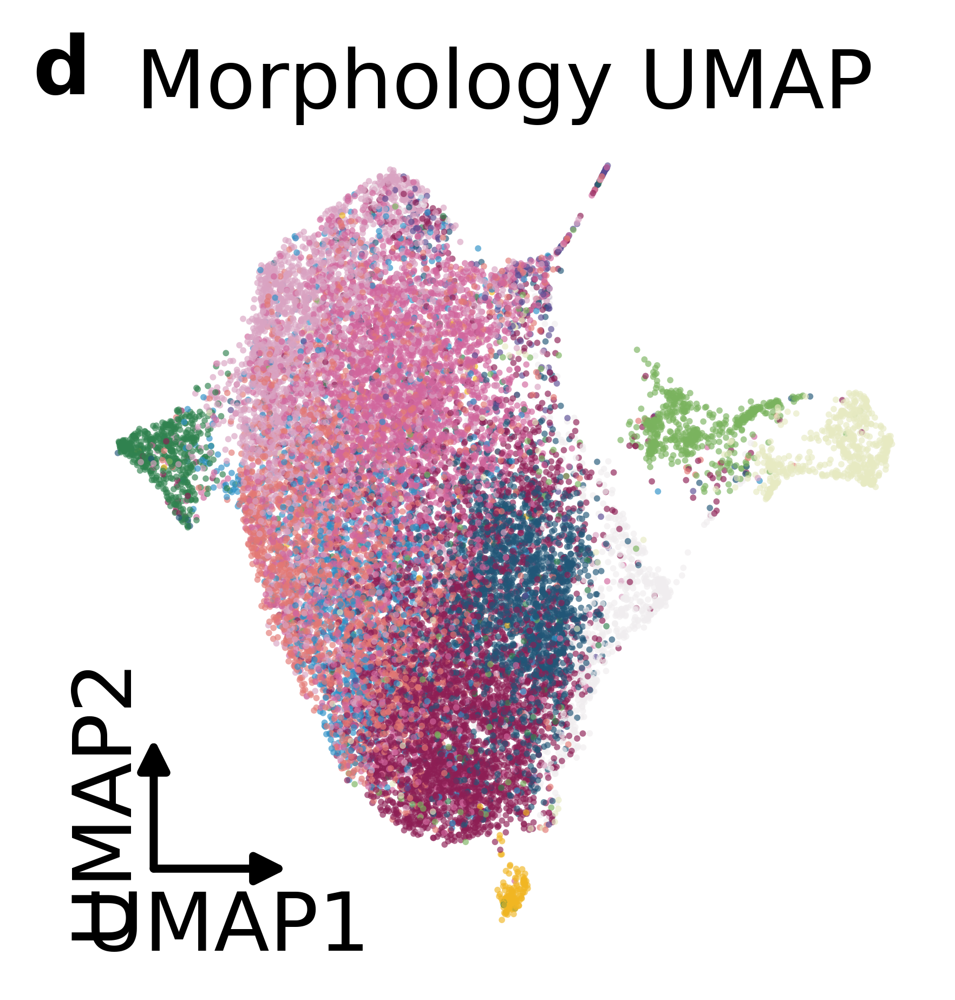

saved panel: /data/hulei/OmicOS/OmicOS_5/figures/main_figure/d_morphology_umap.pdf


In [9]:
g32 = read_csv(P3 / "tables" / "gigapath_domains_32um_omicos3.csv")
fig, ax = plt.subplots(figsize=(3.3, 3.3))
panel_label(ax, "d")
categorical_umap(ax, g32, "smoothed_domain", "Morphology UMAP",legend=False,palette=DOMAIN_COLOR_MAP_12,)
finish_notebook_panel(fig, "main_figure", "d", "morphology_umap")

# Figure E

In [10]:
def draw_representative_tiles(
    fig,
    subspec,
    df,
    n=6,
    crop_size=384,
    fontsize=15,
    title_pad=8,
    wspace=-0.1,
    hspace=0.24,
    border=True,
    border_linewidth=1.2,
):
    rows = representative_tile_rows(df, n=n)
    rows.to_csv(TAB / "representative_tile_sources_omicos5.csv", index=False)

    # 原来 hspace=0.10 太小，第二行标题会贴到第一行图片。
    # 这里适当增大上下间距。
    gs = subspec.subgridspec(
        2,
        3,
        wspace=wspace,
        hspace=hspace,
    )

    axes = []

    for i, (_, row) in enumerate(rows.iterrows()):
        ax = fig.add_subplot(gs[i // 3, i % 3])

        crop = crop_btf_region(
            row["center_x"],
            row["center_y"],
            size=crop_size,
        )

        ax.imshow(crop)
        ax.set_title(
            f"D{row['smoothed_domain']} | {row['marker_proxy_group']}",
            fontsize=fontsize,
            pad=title_pad,
        )

        # 先清理坐标轴刻度和原始 spine。
        clean_axis(ax)

        # 每张小图加黑色边框。
        # 不使用 spine，是因为 clean_axis() 会把 spine 隐藏掉。
        if border:
            ax.add_patch(
                Rectangle(
                    (0, 0),
                    1,
                    1,
                    transform=ax.transAxes,
                    fill=False,
                    edgecolor="black",
                    linewidth=border_linewidth,
                    zorder=10,
                    clip_on=False,
                )
            )

        axes.append(ax)

    # panel_label() 原函数本身已经是 fontsize=18。
    panel_label(axes[0], "e")

    return axes

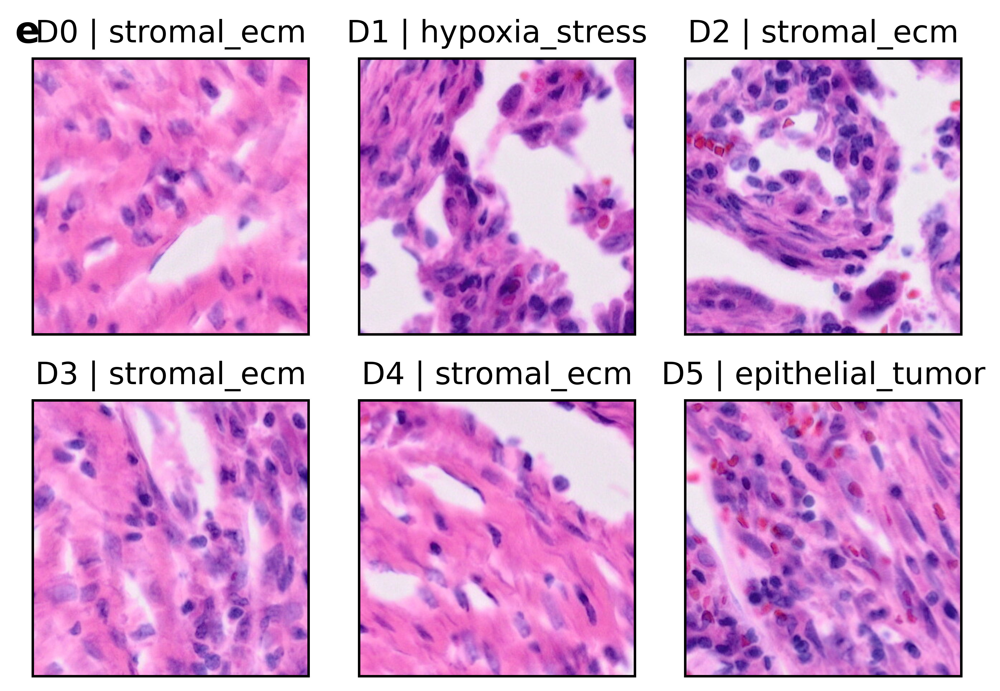

saved panel: /data/hulei/OmicOS/OmicOS_5/figures/main_figure/e_representative_tiles.pdf


In [11]:
g32 = read_csv(P3 / "tables" / "gigapath_domains_32um_omicos3.csv")
fig = plt.figure(figsize=(8.8, 5.5))
gs = fig.add_gridspec(1, 1)
draw_representative_tiles(fig, gs[0, 0], g32)
finish_notebook_panel(fig, "main_figure", "e", "representative_tiles")

# Figure F

In [12]:
def categorical_spatial(
    ax,
    df,
    column,
    title,
    x="center_x",
    y="center_y",
    size=4.0,
    palette=None,
    legend=True,
    fontsize=18,
    draw_border=True,
    border_pad_frac=0.006,
    legend_reserved_frac=0.24,
):
    vals = df[column].astype(str)
    cats = sorted(vals.dropna().unique(), key=natural_key)

    if palette is None:
        color_map = {
            cat: DOMAIN_COLORS[i % len(DOMAIN_COLORS)]
            for i, cat in enumerate(cats)
        }
    else:
        color_map = {
            cat: palette.get(cat, "#999999")
            for cat in cats
        }

    # 数据范围
    x0, x1 = df[x].min(), df[x].max()
    y0, y1 = df[y].min(), df[y].max()

    dx = x1 - x0
    dy = y1 - y0

    pad_x = dx * border_pad_frac
    pad_y = dy * border_pad_frac

    # 给右侧 legend 预留区域
    legend_space = dx * legend_reserved_frac if legend and len(cats) <= 12 else 0.0

    # 主图散点
    ax.scatter(
        df[x],
        df[y],
        c=vals.map(color_map).fillna("#cccccc"),
        s=size,
        linewidths=0,
        rasterized=True,
    )

    # 边框（如果你前面已经加过这个需求，这里可以保留）
    if draw_border:
        ax.add_patch(
            Rectangle(
                (x0, y0),
                dx,
                dy,
                fill=False,
                edgecolor="black",
                linewidth=1.2,
                zorder=10,
                clip_on=False,
            )
        )

    # 固定显示范围：右侧额外留出 legend 空间
    ax.set_xlim(x0 - pad_x, x1 + pad_x + legend_space)
    ax.set_ylim(y1 + pad_y, y0 - pad_y)

    ax.set_aspect("equal", adjustable="box")
    ax.set_title(title, fontsize=fontsize, pad=8)

    clean_axis(ax)

    # legend 放在右边留白区域
    if legend and len(cats) <= 12:
        handles = [
            Line2D(
                [0],
                [0],
                marker="o",
                color="none",
                markerfacecolor=color_map[c],
                markeredgecolor="black",
                markeredgewidth=1.2,
                markersize=15,
                label=str(c),
            )
            for c in cats
        ]

        ax.legend(
            handles=handles,
            loc="center left",
            bbox_to_anchor=(0.82, 0.5),
            bbox_transform=ax.transAxes,
            frameon=False,
            ncol=2,
            fontsize=fontsize,
            handletextpad=0.35,
            columnspacing=0.85,
            labelspacing=0.40,
            borderaxespad=0.0,
        )

ST_DOMAIN_PALETTE = {
    "0": "#8D1E54",  # 深酒红
    "1": "#D98DB8",  # 粉色
    "2": "#D8C5CF",  # 浅粉灰
    "3": "#E07A6A",  # 珊瑚红
    "4": "#2C5D86",  # 深蓝
    "5": "#4BA3D9",  # 蓝色
    "6": "#E7EAC2",  # 浅灰
    "7": "#49A05A",  # 绿色
}

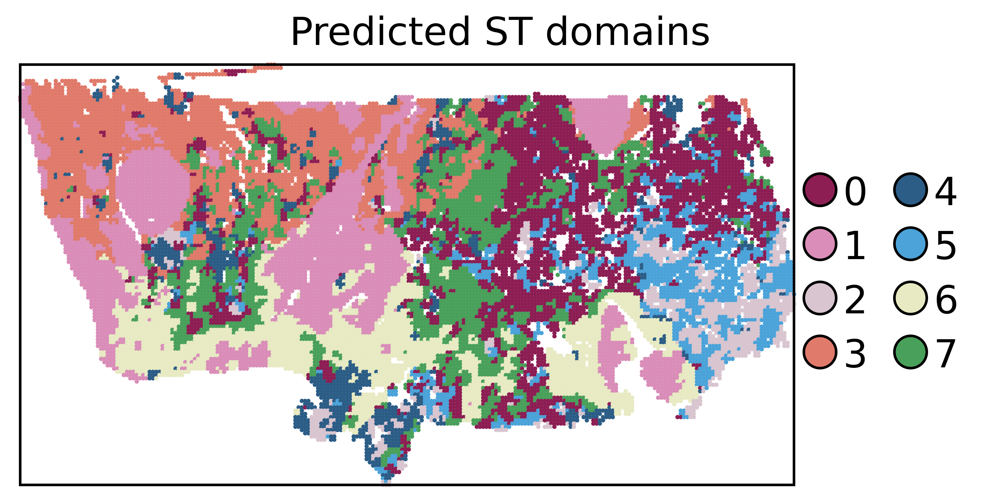

saved panel: /data/hulei/OmicOS/OmicOS_5/figures/main_figure/f_predicted_st_domains.pdf


In [13]:
g32 = read_csv(P3 / "tables" / "gigapath_domains_32um_omicos3.csv")
fig, ax = plt.subplots(figsize=(8, 5))
categorical_spatial(
    ax,
    g32,
    "refined_predicted_domain",
    "Predicted ST domains",
    palette=ST_DOMAIN_PALETTE,
)
finish_notebook_panel(fig, "main_figure", "f", "predicted_st_domains")

# ST predicted UMAP helper


In [14]:
def add_st_umap_coordinates(df, feature_cols=MARKER_GROUPS, out_path=None):
    if out_path is None:
        out_path = TAB / "predicted_st_marker_umap_32um_omicos5.csv"
    out_path = Path(out_path)
    missing = [col for col in feature_cols if col not in df.columns]
    if missing:
        raise KeyError(f"Missing ST marker columns for UMAP: {missing}")
    if len(df) < 3:
        raise ValueError(f"Need at least 3 tiles for ST UMAP, got {len(df)}")

    values = df[list(feature_cols)].apply(pd.to_numeric, errors="coerce")
    bad_rows = int(values.isna().any(axis=1).sum())
    if bad_rows:
        raise ValueError(f"ST UMAP input contains non-numeric/NaN values in {bad_rows} rows")

    cache_cols = ["tile_id", "st_umap1", "st_umap2", *feature_cols]
    if out_path.exists():
        cached = read_csv(out_path)
        cache_ok = all(col in cached.columns for col in cache_cols)
        if cache_ok and len(cached) == len(df) and cached["tile_id"].astype(str).equals(df["tile_id"].astype(str)):
            cached_values = cached[list(feature_cols)].to_numpy(dtype=float)
            if np.allclose(cached_values, values.to_numpy(dtype=float), rtol=0, atol=1e-12):
                out = df.copy()
                out["st_umap1"] = cached["st_umap1"].to_numpy(dtype=float)
                out["st_umap2"] = cached["st_umap2"].to_numpy(dtype=float)
                return out
        print(f"recomputing ST UMAP: cache is missing, stale, or not aligned with current tiles ({out_path})")

    from sklearn.preprocessing import StandardScaler
    from umap import UMAP

    scaled = StandardScaler().fit_transform(values.to_numpy(dtype=float))
    n_neighbors = min(30, max(2, len(df) - 1))
    coords = UMAP(
        n_components=2,
        n_neighbors=n_neighbors,
        min_dist=0.20,
        metric="euclidean",
        random_state=0,
        n_jobs=1,
    ).fit_transform(scaled)

    out = df.copy()
    out["st_umap1"] = coords[:, 0]
    out["st_umap2"] = coords[:, 1]
    out_path.parent.mkdir(parents=True, exist_ok=True)
    out[cache_cols].to_csv(out_path, index=False)
    print(f"saved ST UMAP coordinates: {out_path}")
    return out


# Figure F2


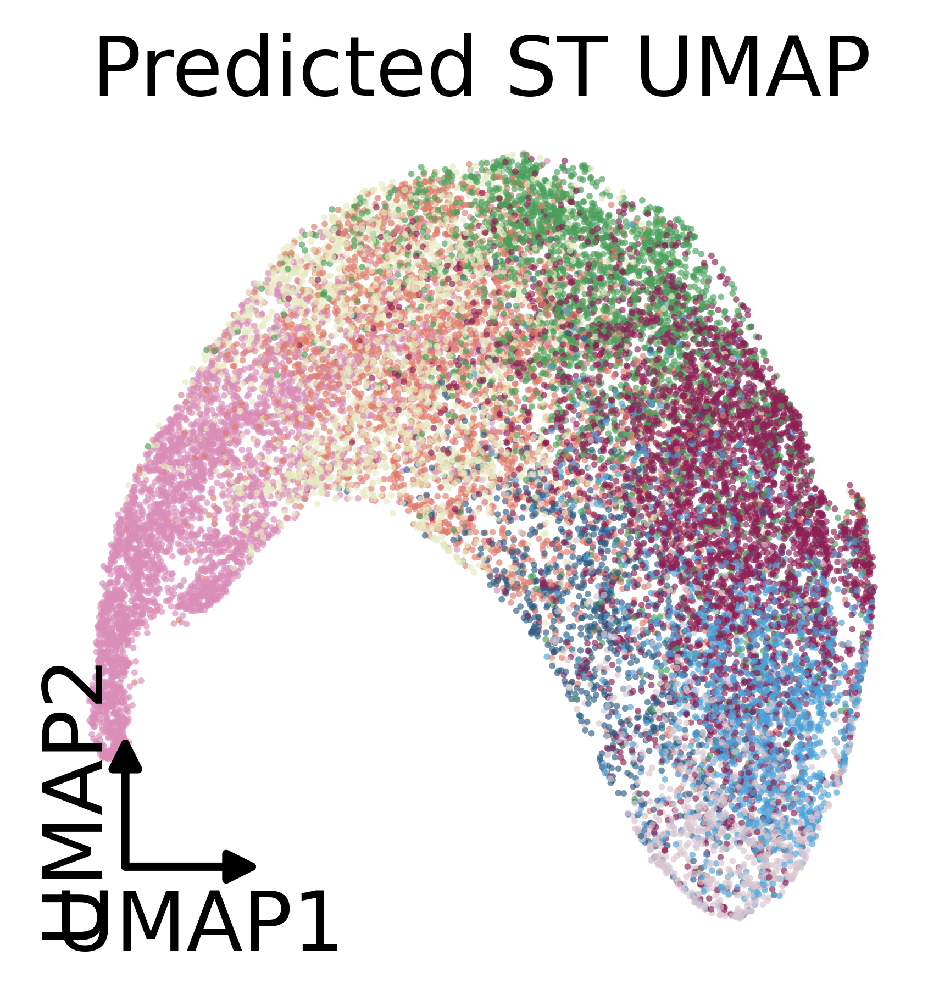

saved panel: /data/hulei/OmicOS/OmicOS_5/figures/main_figure/f2_predicted_st_umap.pdf


In [15]:
g32 = read_csv(P3 / "tables" / "gigapath_domains_32um_omicos3.csv")
g32 = add_st_umap_coordinates(g32)
fig, ax = plt.subplots(figsize=(3.3, 3.3))
categorical_umap(
    ax,
    g32,
    "refined_predicted_domain",
    "Predicted ST UMAP",
    x="st_umap1",
    y="st_umap2",
    legend=False,
    palette=ST_DOMAIN_PALETTE,
)
finish_notebook_panel(fig, "main_figure", "f2", "predicted_st_umap")


# Figure G

In [16]:
from matplotlib.patches import Rectangle
import matplotlib as mpl


def continuous_spatial(
    ax,
    df,
    column,
    title,
    x="center_x",
    y="center_y",
    cmap="magma",
    size=1.5,
    fontsize=18,
    vmin=None,
    vmax=None,
    quantile_clip=(0.02, 0.98),
    draw_border=True,
    border_pad_frac=0.006,
    border_linewidth=1.2,
):
    vals = df[column].astype(float)

    # 如果外部没有传入 vmin/vmax，就使用当前 marker 自己的 2%-98% 分位数
    if vmin is None or vmax is None:
        q1, q2 = vals.quantile(list(quantile_clip)).tolist()
        if vmin is None:
            vmin = q1
        if vmax is None:
            vmax = q2

    x0, x1 = df[x].min(), df[x].max()
    y0, y1 = df[y].min(), df[y].max()

    dx = x1 - x0
    dy = y1 - y0

    pad_x = dx * border_pad_frac
    pad_y = dy * border_pad_frac

    im = ax.scatter(
        df[x],
        df[y],
        c=vals,
        s=size,
        linewidths=0,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        rasterized=True,
    )

    # 固定空间范围，避免不同子图自动缩放略有差异
    ax.set_xlim(x0 - pad_x, x1 + pad_x)
    ax.set_ylim(y1 + pad_y, y0 - pad_y)

    ax.set_aspect("equal", adjustable="box")
    ax.set_title(title, fontsize=fontsize, pad=8)

    clean_axis(ax)

    # clean_axis() 会隐藏 spine，所以边框用 Rectangle 单独画
    if draw_border:
        ax.add_patch(
            Rectangle(
                (0, 0),
                1,
                1,
                transform=ax.transAxes,
                fill=False,
                edgecolor="black",
                linewidth=border_linewidth,
                zorder=10,
                clip_on=False,
            )
        )

    return im

def add_shared_colorbar(
    fig,
    cmap="magma",
    vmin=0.0,
    vmax=1.0,
    label="Marker score",
    fontsize=18,
    cax_position=(0.92, 0.18, 0.018, 0.64),
):
    norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
    sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])

    cax = fig.add_axes(cax_position)
    cax._skip_panel = True

    cb = fig.colorbar(sm, cax=cax)

    cb.ax.tick_params(
        labelsize=fontsize,
        length=3,
        width=1.0,
        pad=4,
    )

    if label:
        cb.set_label(label, fontsize=fontsize, labelpad=10)

    cb.outline.set_linewidth(1.0)

    return cb


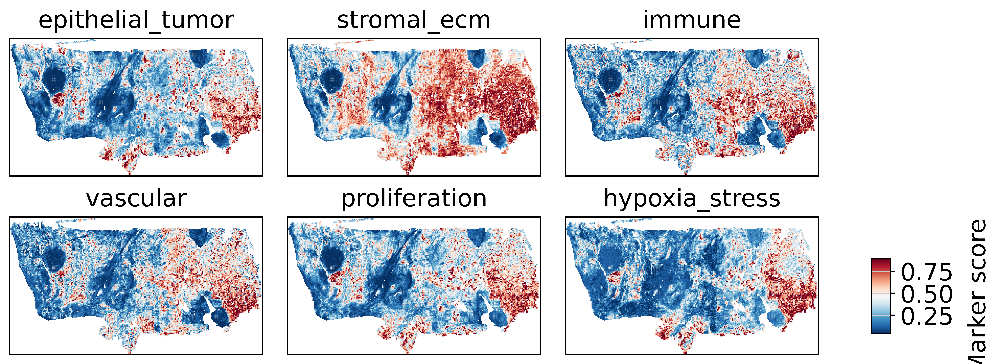

saved panel: /data/hulei/OmicOS/OmicOS_5/figures/main_figure/g_marker_spatial_gradients.pdf


In [17]:
g32 = read_csv(P3 / "tables" / "gigapath_domains_32um_omicos3.csv")
fig = plt.figure(figsize=(9.2*1.5/1.25, 5.4/1.25))
gs = fig.add_gridspec(2,3, wspace=0.015, hspace=0.3)
for i, marker in enumerate(MARKER_GROUPS):
    ax = fig.add_subplot(gs[i // 3, i % 3])
    im = continuous_spatial(ax, g32, marker, marker, cmap="RdBu_r", size=1.1)

all_marker_values = g32[MARKER_GROUPS].to_numpy(dtype=float).ravel()
global_vmin = np.nanquantile(all_marker_values, 0.02)
global_vmax = np.nanquantile(all_marker_values, 0.98)
# 单独生成一个共享 colorbar
add_shared_colorbar(
    fig,
    cmap="RdBu_r",
    vmin=global_vmin,
    vmax=global_vmax,
    label="Marker score",
    fontsize=18,
    cax_position=(1, 0.20, 0.018, 0.18),
)

finish_notebook_panel(fig, "main_figure", "g", "marker_spatial_gradients")

# Figure H

In [18]:
def heatmap(
    ax,
    frame,
    title,
    cmap="viridis",
    vmin=None,
    vmax=None,
    annotate=False,
    fmt=".2f",
    fontsize=18,
    x_label=None,
    y_label=None,
    remove_grid=True,
    tick_length=4,
    tick_width=2,
    tick_direction="out",
    border_width=2,
):
    im = ax.imshow(
        frame.to_numpy(dtype=float),
        aspect="auto",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        interpolation="nearest",
    )

    ax.set_title(title, fontsize=fontsize, pad=10)

    ax.set_xticks(range(frame.shape[1]))
    ax.set_xticklabels(
        [str(c) for c in frame.columns],
        rotation=0,
        ha="center",
        fontsize=fontsize,
    )

    ax.set_yticks(range(frame.shape[0]))
    ax.set_yticklabels(
        [str(i) for i in frame.index],
        fontsize=fontsize,
    )

    if x_label is not None:
        ax.set_xlabel(x_label, fontsize=fontsize, labelpad=10)

    if y_label is not None:
        ax.set_ylabel(y_label, fontsize=fontsize, labelpad=10)

    # x/y 轴主刻度线
    ax.tick_params(
        axis="both",
        which="major",
        length=tick_length,
        width=tick_width,
        direction=tick_direction,
        labelsize=fontsize,
        bottom=True,
        top=False,
        left=True,
        right=False,
    )

    # 移除网格线和 minor tick
    if remove_grid:
        ax.grid(False)
        ax.set_xticks([], minor=True)
        ax.set_yticks([], minor=True)
        ax.tick_params(which="minor", length=0)

    # 边框
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(border_width)
        spine.set_edgecolor("black")

    # 可选：热图内部数值标注
    if annotate and frame.shape[0] * frame.shape[1] <= 90:
        for i in range(frame.shape[0]):
            for j in range(frame.shape[1]):
                val = frame.iloc[i, j]
                if np.isfinite(val):
                    ax.text(
                        j,
                        i,
                        format(val, fmt),
                        ha="center",
                        va="center",
                        fontsize=fontsize,
                    )

    return im

In [19]:
import matplotlib as mpl


def add_standalone_colorbar(
    fig,
    cmap,
    vmin,
    vmax,
    label=None,
    fontsize=18,
    cax_position=(0.88, 0.20, 0.025, 0.60),
):
    norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
    sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])

    cax = fig.add_axes(cax_position)
    cax._skip_panel = True

    cb = fig.colorbar(sm, cax=cax)

    # colorbar 刻度文字 18
    cb.ax.tick_params(
        labelsize=fontsize,
        length=4,
        width=2.0,
        pad=5,
    )

    # 边框线宽设置为 2
    for spine in cb.ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(2)
        spine.set_edgecolor("black")
        
    for tick in cb.ax.get_yticklabels():
        tick.set_fontsize(fontsize)

    # colorbar label 18
    if label is not None:
        cb.set_label(
            label,
            fontsize=fontsize,
            labelpad=12,
        )

    cb.outline.set_linewidth(1.0)

    return cb

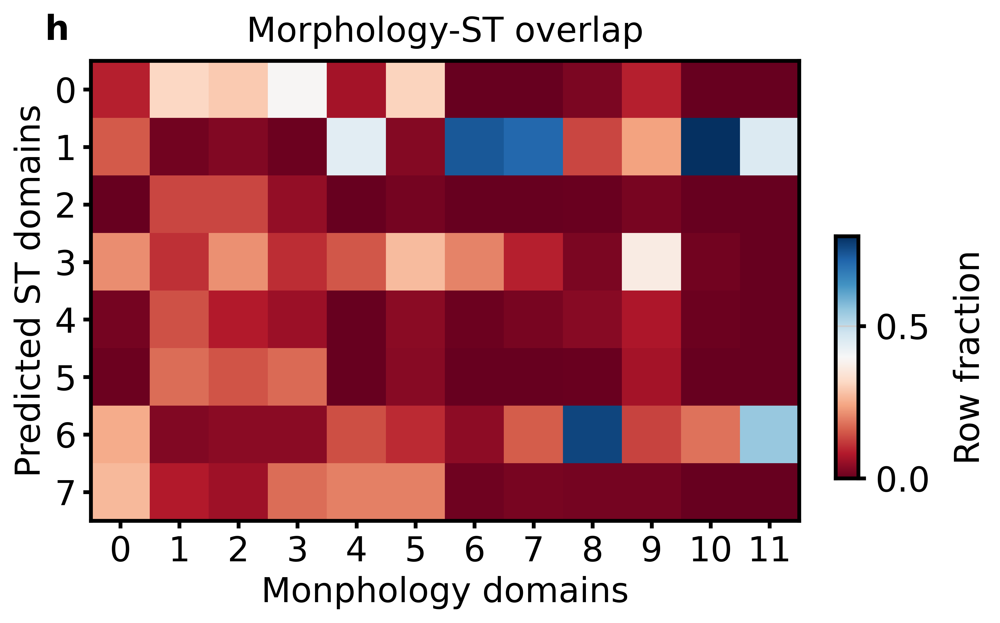

saved panel: /data/hulei/OmicOS/OmicOS_5/figures/main_figure/h_morphology_st_overlap.pdf


In [20]:
g32 = read_csv(P3 / "tables" / "gigapath_domains_32um_omicos3.csv")
fig, ax = plt.subplots(figsize=(6.6, 4.4))
panel_label(ax, "h")
overlap = pd.crosstab(g32["smoothed_domain"].astype(str), g32["refined_predicted_domain"].astype(str), normalize="index")
overlap = overlap.sort_index(key=lambda x: [natural_key(v) for v in x]).reindex(columns=sorted(overlap.columns, key=natural_key))
im = heatmap(ax, overlap.T, "Morphology-ST overlap", cmap="RdBu", vmin=0, vmax=max(0.01, overlap.to_numpy().max()))
plt.xlabel('Monphology domains',fontsize=18)
plt.ylabel('Predicted ST domains',fontsize=18)
ax.grid(False)

add_standalone_colorbar(
    fig,
    cmap="RdBu",
    vmin=0,
    vmax=max(0.01, overlap.to_numpy().max()),
    label="Row fraction",
    fontsize=18,
    cax_position=(1, 0.22, 0.025, 0.4),
)



finish_notebook_panel(fig, "main_figure", "h", "morphology_st_overlap")

# Figure J

In [21]:
def domain_ntiles_bar(
    ax,
    g32,
    domains,
    fontsize=18,
    cmap="Reds",
    edgecolor="black",
    linewidth=2,
    tick_length=6,
    tick_width=2,
    border_width=2,
    bar_width=1.0,
    show_xtick_labels=False,
):
    # 统计每个 domain 的 n_tiles
    domain_ints = [int(str(d).replace("D", "")) for d in domains]

    n_tiles = (
        g32["smoothed_domain"]
        .astype(int)
        .value_counts()
        .reindex(domain_ints, fill_value=0)
    )

    x = np.arange(len(domain_ints))
    values = n_tiles.values.astype(float)

    # 红色渐变：n_tiles 越高，颜色越深
    if values.max() > values.min():
        norm = plt.Normalize(values.min(), values.max())
        colors = plt.get_cmap(cmap)(norm(values))
    else:
        colors = plt.get_cmap(cmap)(np.full_like(values, 0.6, dtype=float))

    ax.bar(
        x,
        values,
        width=bar_width,
        color=colors,
        edgecolor=edgecolor,
        linewidth=linewidth,
        align="center",
    )

    # 关键：和 heatmap 的 imshow 默认列边界完全一致
    # heatmap 第 0 列边界是 -0.5 到 0.5
    # 第 n-1 列边界是 n-1.5 到 n-0.5
    ax.set_xlim(-0.5, len(domain_ints) - 0.5)

    ax.set_ylabel(
        "n tiles",
        fontsize=fontsize,
        labelpad=8,
    )

    ax.set_xticks(x)
    ax.tick_params(
        axis="x",
        which="both",
        labelbottom=False,
        )


    if show_xtick_labels:
        ax.set_xticklabels(
            [f"D{d}" for d in domain_ints],
            fontsize=fontsize,
            rotation=0,
        )
        bottom_ticks = True
    else:
        ax.set_xticklabels([])
        bottom_ticks = False

    ax.tick_params(
        axis="both",
        which="major",
        labelsize=fontsize,
        length=tick_length,
        width=tick_width,
        direction="out",
        bottom=bottom_ticks,
        left=True,
        top=False,
        right=False,
    )

    # 只保留左侧和下侧边框
    ax.spines["left"].set_visible(True)
    ax.spines["left"].set_linewidth(border_width)
    ax.spines["left"].set_edgecolor("black")

    ax.spines["bottom"].set_visible(True)
    ax.spines["bottom"].set_linewidth(border_width)
    ax.spines["bottom"].set_edgecolor("black")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(False)

    return n_tiles

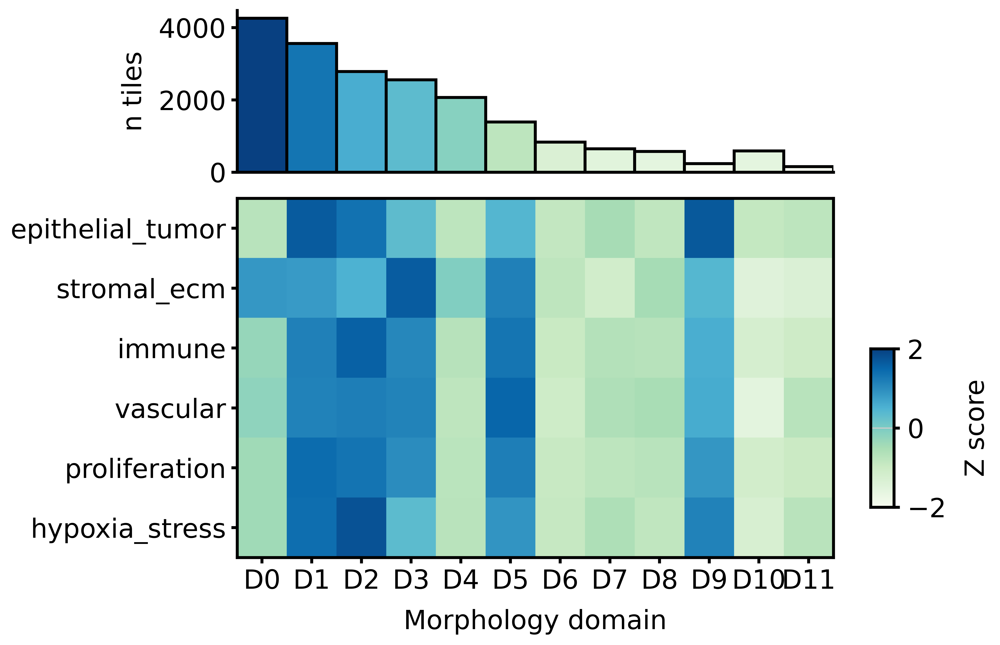

saved panel: /data/hulei/OmicOS/OmicOS_5/figures/main_figure/j_visium_marker_validation.pdf


In [127]:
validation = read_csv(
    P3 / "tables" / "visium_marker_validation_by_gigapath_domain_omicos3.csv"
)

g32 = read_csv(
    P3 / "tables" / "gigapath_domains_32um_omicos3.csv"
)

domains = sorted(
    validation["smoothed_domain"].unique(),
    key=natural_key,
)

val_pivot = (
    validation
    .pivot(
        index="marker_group",
        columns="smoothed_domain",
        values="mean_expression",
    )
    .reindex(index=MARKER_GROUPS)
    .reindex(columns=domains)
)

val_pivot.columns = [f"D{int(d)}" for d in val_pivot.columns]

fig = plt.figure(figsize=(8.8, 6.8))

gs = fig.add_gridspec(
    2,
    1,
    height_ratios=[1.35, 3],
    hspace=0.10,
    right=0.82,
)

ax_bar = fig.add_subplot(gs[0, 0])
ax_hm = fig.add_subplot(gs[1, 0], sharex=ax_bar)


# 上方 n_tiles 柱状图
domain_ntiles_bar(
    ax_bar,
    g32,
    domains=domains,
    fontsize=18,
    cmap="GnBu",
    linewidth=2,
    tick_length=4,
    tick_width=2,
    border_width=2,
    bar_width=1.0,
    show_xtick_labels=False,
)

# 下方 heatmap
im = heatmap(
    ax_hm,
    row_zscore(val_pivot),
    "",
    cmap="GnBu",
    vmin=-2,
    vmax=2,
    fontsize=18,
    x_label="Morphology domain",
    y_label="",
    tick_length=4,
    tick_width=2,
    border_width=2,
)

# 再次强制两个 axes 的 x 范围一致
n_domains = len(domains)
ax_bar.set_xlim(-0.5, n_domains - 0.5)
ax_hm.set_xlim(-0.5, n_domains - 0.5)

add_standalone_colorbar(
    fig,
    cmap="GnBu",
    vmin=-2,
    vmax=2,
    label="Z score",
    fontsize=18,
    cax_position=(0.86, 0.22, 0.025, 0.22),
)

finish_notebook_panel(
    fig,
    "main_figure",
    "j",
    "visium_marker_validation"
)

In [23]:
g32 = read_csv(P3 / "tables" / "gigapath_domains_32um_omicos3.csv")
g32 = add_st_umap_coordinates(g32)
multi = read_csv(P3 / "tables" / "gigapath_multiscale_concordance_omicos3.csv")
metrics = read_csv(P3 / "tables" / "gigapath32_concordance_metrics_omicos3.csv")
validation = read_csv(P3 / "tables" / "visium_marker_validation_by_gigapath_domain_omicos3.csv")
assoc_v1 = read_csv(P1 / "tables" / "morphology_gene_association_v1_1.csv")
assoc_plip = read_csv(P2 / "tables" / "plip_morphology_gene_association_omicos2.csv")
assoc_lazyslide = read_csv(P1 / "tables" / "lazyslide_morphology_gene_association_v1_1.csv")
summary_v1 = read_json(P1 / "artifacts" / "final_summary_v1_1.json")

fig = plt.figure(figsize=(16.2, 13.8), constrained_layout=False)
gs = fig.add_gridspec(4, 3, height_ratios=[0.95, 1.0, 1.10, 0.98], wspace=0.18, hspace=0.24)
fig.subplots_adjust(left=0.035, right=0.992, top=0.974, bottom=0.045)

ax = fig.add_subplot(gs[0, 0])
panel_label(ax, "A")
clean_axis(ax)
ax.set_title("HE dual-path workflow")
steps = [
    ("H&E", "GigaPath morphology\n32 um domains"),
    ("Predicted ST", "refined molecular\ndomains"),
    ("Markers", "tumor + stromal +\nimmune + vascular"),
    ("Validation", "Visium HD and\nconcordance"),
]
for i, (head, body) in enumerate(steps):
    y = 0.78 - i * 0.22
    ax.add_patch(Rectangle((0.08, y - 0.10), 0.72, 0.15, facecolor=["#e8f1fb", "#fff3c4", "#e4f4e5", "#f1f1f1"][i], edgecolor="#333333", lw=0.8))
    ax.text(0.16, y - 0.03, head, ha="left", va="center", fontweight="bold", fontsize=9.5)
    ax.text(0.40, y - 0.03, body, ha="left", va="center", fontsize=8.5)
    if i < len(steps) - 1:
        ax.add_patch(FancyArrowPatch((0.44, y - 0.13), (0.44, y - 0.19), arrowstyle="->", mutation_scale=10, lw=1))
ax.text(0.08, 0.02, f"Tiles: {len(g32):,}; selected scale: 32 um", ha="left", va="bottom")

ax = fig.add_subplot(gs[0, 1])
panel_label(ax, "B")
draw_he_footprint(ax, g32)

ax = fig.add_subplot(gs[0, 2])
panel_label(ax, "C")
categorical_spatial(ax, g32, "smoothed_domain", "GigaPath 32 um morphology domains")

ax = fig.add_subplot(gs[1, 0])
panel_label(ax, "D")
categorical_umap(ax, g32, "smoothed_domain", "Morphology UMAP")

draw_representative_tiles(fig, gs[1, 1], g32)

pred_st_gs = gs[1, 2].subgridspec(1, 2, width_ratios=[1.35, 1.0], wspace=0.08)

ax = fig.add_subplot(pred_st_gs[0, 0])
panel_label(ax, "F")
categorical_spatial(
    ax,
    g32,
    "refined_predicted_domain",
    "Refined predicted ST domains",
    palette=ST_DOMAIN_PALETTE,
    legend=False,
    size=2.2,
    fontsize=8.5,
)

ax = fig.add_subplot(pred_st_gs[0, 1])
categorical_umap(
    ax,
    g32,
    "refined_predicted_domain",
    "Predicted ST UMAP",
    x="st_umap1",
    y="st_umap2",
    palette=ST_DOMAIN_PALETTE,
    legend=False,
    size=2.0,
    fontsize=8.5,
)

marker_gs = gs[2, :].subgridspec(2, 3, wspace=0.075, hspace=0.16)
for i, marker in enumerate(MARKER_GROUPS):
    ax = fig.add_subplot(marker_gs[i // 3, i % 3])
    im = continuous_spatial(ax, g32, marker, marker, cmap="magma", size=1.1)
    if i == 0:
        panel_label(ax, "G")
    add_colorbar(fig, im, ax)

ax = fig.add_subplot(gs[3, 0])
panel_label(ax, "H")
overlap = pd.crosstab(g32["smoothed_domain"].astype(str), g32["refined_predicted_domain"].astype(str), normalize="index")
overlap = overlap.sort_index(key=lambda x: [natural_key(v) for v in x]).reindex(columns=sorted(overlap.columns, key=natural_key))
overlap.to_csv(TAB / "gigapath32_vs_predicted_st_overlap_rowfrac_omicos5.csv")
im = heatmap(ax, overlap, "Morphology-ST overlap", cmap="YlGnBu", vmin=0, vmax=max(0.01, overlap.to_numpy().max()))
add_colorbar(fig, im, ax, "row fraction")

ax = fig.add_subplot(gs[3, 1])
panel_label(ax, "I")
assoc = assoc_v1.merge(assoc_plip, on="marker_group", how="outer").merge(assoc_lazyslide, on="marker_group", how="outer").fillna(0)
assoc = assoc.set_index("marker_group").reindex(MARKER_GROUPS).dropna(how="all")
assoc.columns = ["v1 morphology", "PLIP semantics", "LazySlide domains"]
assoc.to_csv(TAB / "marker_association_integrated_omicos5.csv")
y = np.arange(len(assoc))
for k, col in enumerate(assoc.columns):
    ax.barh(y + (k - 1) * 0.24, assoc[col], height=0.23, label=col, color=["#1f77b4", "#ffbf00", "#2ca02c"][k])
ax.set_yticks(y)
ax.set_yticklabels(assoc.index)
ax.set_xlabel("eta squared")
ax.set_title("Marker association across paths")
ax.legend(frameon=False)

ax = fig.add_subplot(gs[3, 2])
panel_label(ax, "J")
val_pivot = validation.pivot(index="marker_group", columns="smoothed_domain", values="mean_expression").reindex(index=MARKER_GROUPS)
im = heatmap(ax, row_zscore(val_pivot), "Visium HD marker validation", cmap="RdBu_r", vmin=-2, vmax=2)
add_colorbar(fig, im, ax, "row z")

save_and_display(fig, "main_figure_omicos5")


saved: /data/hulei/OmicOS/OmicOS_5/figures/main_figure_omicos5.png
saved: /data/hulei/OmicOS/OmicOS_5/figures/main_figure_omicos5.pdf
